In [1]:
import pandas as pd
import numpy as np
import config
import os

import kaplanmeier as km
from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from matplotlib import pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess


# Setup

In [2]:
df = pd.read_csv(config.DATA_PATH)
df_smpl = df.sample(frac=0.75, random_state=config.SEED) 
df_smpl.head()

,id,status,time,hg,pap,cvd,stage,treat
336,338,1,14,17.500000,0.799927,yes,stage3,high-dose
267,269,1,40,13.199219,0.599976,no,stage3,high-dose
349,351,1,57,17.500000,0.699951,no,stage3,high-dose
437,439,0,70,13.599609,0.199982,no,stage3,high-dose
24,25,1,42,14.599609,3.899902,no,stage4,high-dose


# Kaplan-Meier Curves

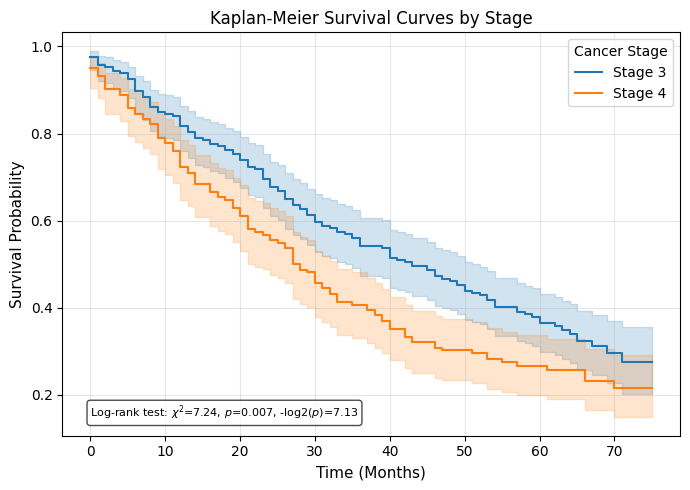

In [3]:
stage3 = df_smpl[df_smpl["stage"]=="stage3"]
stage4   = df_smpl[df_smpl["stage"]=="stage4"]

# Fit models
kmf = KaplanMeierFitter()

plt.figure(figsize=(7,5))
ax = plt.subplot(111)

# Stage 3
kmf.fit(stage3["time"], event_observed=stage3["status"], label="Stage 3")
kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# Stage 4
kmf.fit(stage4["time"], event_observed=stage4["status"], label="Stage 4")
kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# Log-rank test
results = logrank_test(stage3["time"], stage4["time"],
                       event_observed_A=stage3["status"],
                       event_observed_B=stage4["status"])

p_value = results.p_value
chi2 = results.test_statistic
neg_log2_p = -np.log2(p_value)

# Annotate on plot (bottom right corner)
plt.text(
    x=0*max(stage3["time"].max(), stage4["time"].max()),
    y=0.15,
    s=fr"Log-rank test: $\chi^2$={chi2:.2f}, $p$={p_value:.3f}, -log2($p$)={neg_log2_p:.2f}",
    fontsize=8,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.7)
)

# Labels and style
plt.title("Kaplan-Meier Survival Curves by Stage", fontsize=12)
plt.xlabel("Time (Months)", fontsize=11)
plt.ylabel("Survival Probability", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(title="Cancer Stage")
plt.tight_layout()
plt.show()


# Cox regression

In [4]:
duration_col = "time"     # survival time column
event_col    = "status"   # 1 = event/death, 0 = censored

# list covariates of interest 
covariates   = ["hg", "pap", "cvd", "stage", "treat"]
categoricals = {"stage", "treat"} 
alpha = 0.05  # for 95% CI

id,status,time,hg,pap,cvd,stage,treat
1,0,72,13.79882813,0.299987793,no,stage3,low-dose
2,1,1,14.59960938,0.699951172,no,stage3,low-dose
3,1,40,13.3984375,0.299987793,yes,stage3,high-dose
4,1,20,17.59765625,0.899902344,yes,stage3,low-dose

## Model 1 - 5

In [5]:
rows = []
for i, var in enumerate(covariates, start=1):
    cph = CoxPHFitter()
    # Build a formula. If var is categorical, wrap in C()
    term = f"C({var})" if var in categoricals else var
    cph.fit(df_smpl[[duration_col, event_col, var]].dropna(),
            duration_col=duration_col, event_col=event_col,
            formula=term, robust=True)
    summ = cph.summary.copy()
    # lifelines returns one row per coefficient; for categorical, you'll get multiple levels
    summ["Model"] = f"Model {i}"
    summ["Covariate"] = summ.index  # keep full term names (incl. levels)
    summ["HR"] = np.exp(summ["coef"])
    summ["CI lower"] = np.exp(summ["coef lower 95%"])
    summ["CI upper"] = np.exp(summ["coef upper 95%"])
    summ = summ[["Model", "Covariate", "HR", "CI lower", "CI upper", "p"]]
    rows.append(summ)
out = pd.concat(rows, axis=0).reset_index(drop=True)

out.to_csv(os.path.join(config.OUTPUT_PATH, "cox_univariable_results.csv"), index=False)

## Model 6

In [6]:
# Build a multivariable formula combining C() for categorical vars
terms = [f"C({v})" if v in categoricals else v for v in covariates]
formula = " + ".join(terms)
cph6 = CoxPHFitter().fit(df_smpl[[duration_col, event_col] + covariates].dropna(),
        duration_col=duration_col, event_col=event_col,
        formula=formula, robust=True)
summ = cph6.summary.copy()
summ["Model"] = "Model 6 (multivariable)"
summ["Covariate"] = summ.index
summ["HR"] = np.exp(summ["coef"])
summ["CI lower"] = np.exp(summ["coef lower 95%"])
summ["CI upper"] = np.exp(summ["coef upper 95%"])
summ = summ[["Model", "Covariate", "HR", "CI lower", "CI upper", "p"]]

summ.to_csv(os.path.join(config.OUTPUT_PATH, "cox_multivariable_results.csv"), index=False)

In [7]:
cph6.print_summary()

<lifelines.CoxPHFitter: fitted with 376 total observations, 113 right-censored observations>
             duration col = 'time'
                event col = 'status'
          robust variance = True
      baseline estimation = breslow
   number of observations = 376
number of events observed = 263
   partial log-likelihood = -1401.45
         time fit was run = 2025-09-29 20:23:10 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
hg                   -0.13      0.88      0.03           -0.20           -0.06                0.82                0.94
pap                  -0.00      1.00      0.00           -0.00            0.00                1.00                1.00
cvd[T.yes]            0.41      1.50      0.13            0.16            0.66                1.17                1.94
C(stage)[T.stage4]    0.28      1.32      0.13            0.01            0.54                1.01                1.72
C(treat)[T.low-dose]  0.19      1.21      0.15           -0.11            0.48                0.90                1.62
C(treat)[T.placebo]   0.10      1.10      0.16           -0.21            0.41                0.81                1.50

                      cmp to     z      p  -log2(p)
covariate                                          
hg                      0.00 -3.79 <0.005     12.72
pap                     0.00 -0.15   0.88      0.18
cvd[T.yes]              0.00  3.17 <0.005      9.35
C(stage)[T.stage4]      0.00  2.07   0.04      4.69
C(treat)[T.low-dose]    0.00  1.23   0.22      2.21
C(treat)[T.placebo]     0.00  0.61   0.54      0.89
---
Concordance = 0.61
Partial AIC = 2814.90
log-likelihood ratio test = 36.45 on 6 df
-log2(p) of ll-ratio test = 18.76

## Shoenfeld residuals

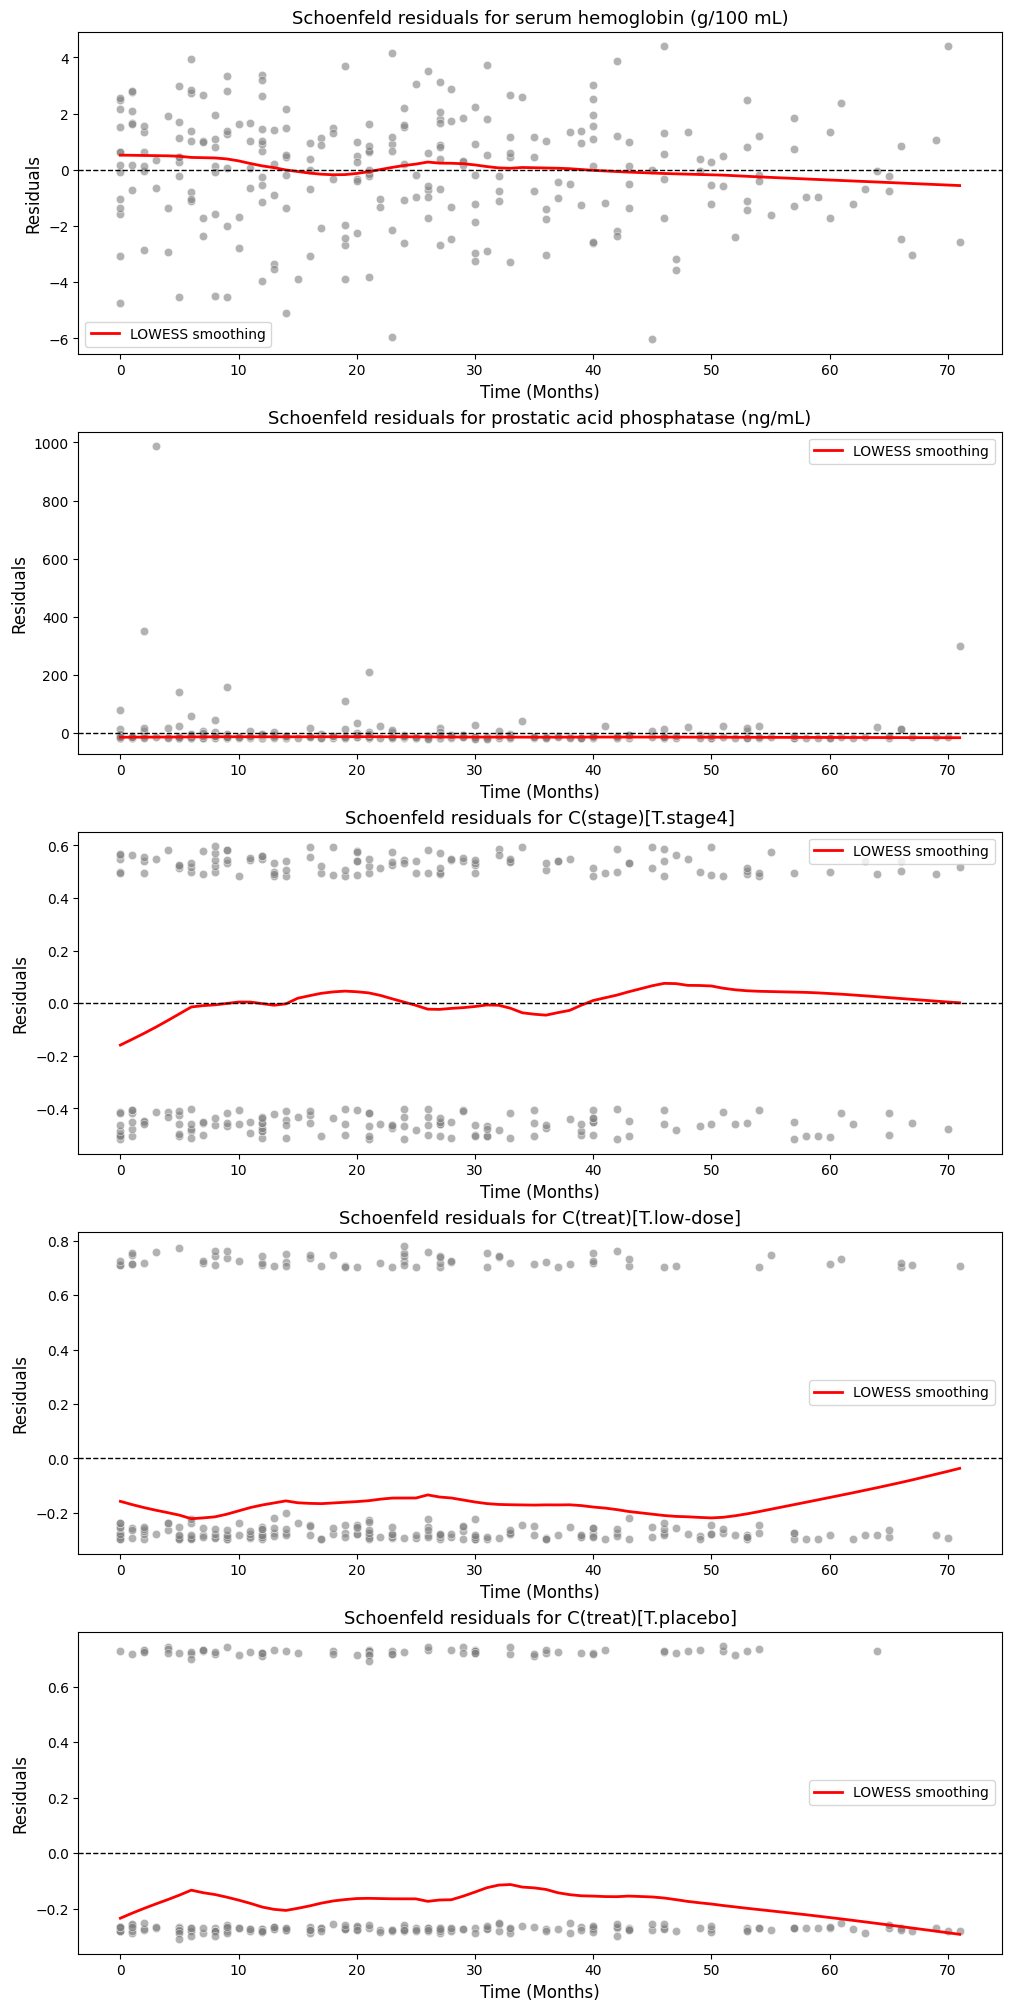

In [ ]:
schoenfeld_resids = cph6.compute_residuals(df_smpl, kind='schoenfeld')

# Extract event times for uncensored observations only
event_times = df_smpl[df_smpl['status'] == 1]['time'].values

# Define covariates to plot
covariates_to_plot = ['hg']
covariates_to_plot = ["hg", "pap", "C(stage)[T.stage4]", "C(treat)[T.low-dose]", "C(treat)[T.placebo]"]

pretty = {
    "hg":  "serum hemoglobin (g/100 mL)",
    "pap": "prostatic acid phosphatase (ng/mL)"
}

# Set up plot
n = len(covariates_to_plot)
fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 4 * n), constrained_layout=True)

# Ensure axes is iterable
if n == 1:
    axes = [axes]

# Plot residuals with LOWESS smoothing for each covariate
for i, covariate in enumerate(covariates_to_plot):
    y = schoenfeld_resids[covariate].values
    x = event_times

    # Compute LOWESS smoothing
    lowess_curve = lowess(y, x, frac=0.3)

    # Scatter plot of residuals
    sns.scatterplot(x=x, y=y, ax=axes[i], color='gray', alpha=0.6)

    # LOWESS smoothed line
    axes[i].plot(lowess_curve[:, 0], lowess_curve[:, 1], color='red', linewidth=2, label='LOWESS smoothing')

    # Zero reference line
    axes[i].axhline(0, linestyle='--', color='black', linewidth=1)

    # Set title and labels
    # axes[i].set_title(f"Schoenfeld residuals for serum hemoglobin (g/100 mL)", fontsize=14)
    axes[i].set_title(f"Schoenfeld residuals for {pretty.get(covariate, covariate)}", fontsize=13)
    axes[i].set_xlabel("Time (Months)", fontsize=12)
    axes[i].set_ylabel("Residuals", fontsize=12)
    axes[i].legend()

# Display the plot
plt.show()

In [12]:
#cph6.check_assumptions(df_smpl, show_plots=True, p_value_threshold=0.05)


## Interest

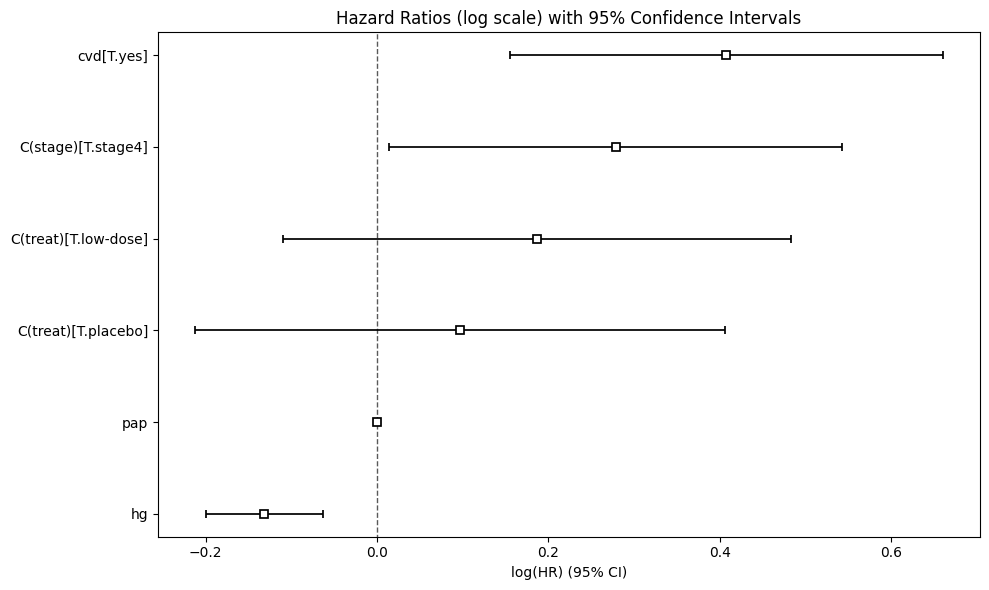

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
cph6.plot(ax=ax)
plt.title("Hazard Ratios (log scale) with 95% Confidence Intervals")
plt.tight_layout()

plt.savefig("cox_ph_coefficient_plot.png")
plt.show()